# 02 — Análise Exploratória dos Dados (EDA)

EDA sobre o dataset construído no notebook 01 (um pedido por linha).

1. Estatísticas descritivas · 2. Distribuição das variáveis · 3. Outliers · 4. Matriz de correlações · 5. Mapa geográfico

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import olist_features as of

TAB = ROOT / "resultados/tabelas"; TAB.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "resultados/graficos"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
data = of.load_dataset()
y = data[of.TARGET]
print(data.shape)

(96164, 36)


## 1. Estatísticas descritivas (média, mediana, desvio padrão…)

In [2]:
cols = [of.TARGET] + of.NUMERIC
desc = data[cols].describe().T.rename(columns={"50%": "mediana", "std": "desvio_padrao", "mean": "media"})
desc = desc[["count", "media", "mediana", "desvio_padrao", "min", "25%", "75%", "max"]]
desc.to_csv(TAB / "02_estatisticas_descritivas.csv")
desc

,count,media,mediana,desvio_padrao,min,25%,75%,max
delivery_time_days,"96,164.00",12.32,10.20,8.37,0.53,6.75,15.59,60.00
products_value_total,"96,164.00",136.89,86.00,208.89,0.85,45.90,149.90,"13,440.00"
freight_value_total,"96,164.00",22.76,17.16,21.52,0.00,13.83,23.99,"1,794.96"
order_value_total,"96,164.00",159.65,105.24,218.61,9.59,61.81,176.16,"13,664.08"
items_count,"96,164.00",1.14,1.00,0.54,1.00,1.00,1.00,21.00
products_count,"96,164.00",1.04,1.00,0.23,1.00,1.00,1.00,8.00
sellers_count,"96,164.00",1.01,1.00,0.12,1.00,1.00,1.00,5.00
seller_states_count,"96,164.00",1.01,1.00,0.07,1.00,1.00,1.00,3.00
same_state_items_fraction,"96,164.00",0.36,0.00,0.48,0.00,0.00,1.00,1.00
weight_g_total,"96,142.00","2,382.67",750.00,"4,760.92",2.00,300.00,"2,050.00","184,400.00"


## 2. Distribuição das variáveis

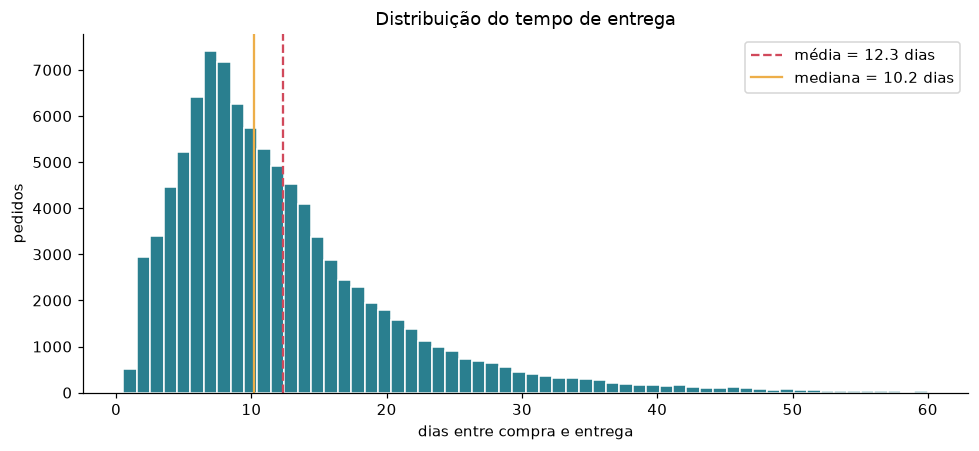

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(y, bins=60, color="#2a7f8f", edgecolor="white")
ax.axvline(y.mean(), color="#d1495b", ls="--", label=f"média = {y.mean():.1f} dias")
ax.axvline(y.median(), color="#edae49", ls="-", label=f"mediana = {y.median():.1f} dias")
ax.set(title="Distribuição do tempo de entrega", xlabel="dias entre compra e entrega", ylabel="pedidos")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "01_distribuicao_alvo.png", dpi=150); plt.show()

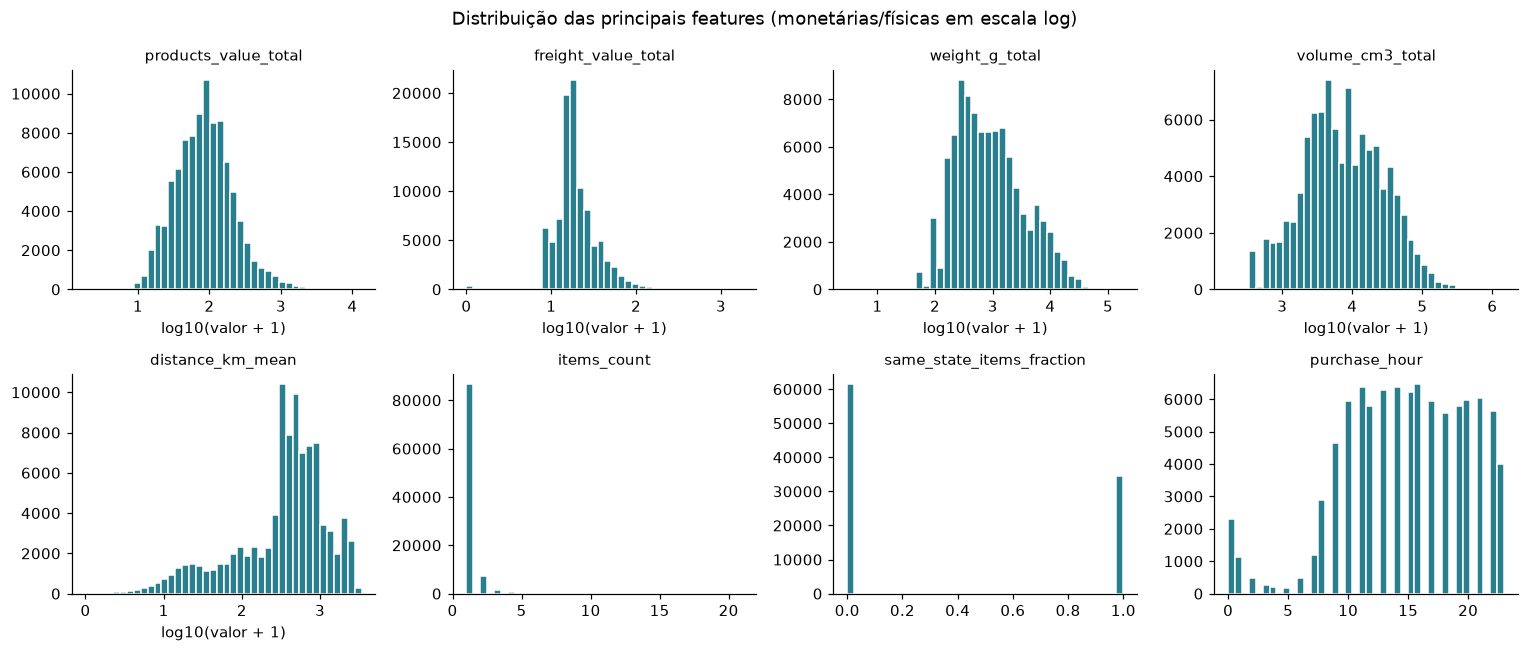

In [4]:
vars_ = ["products_value_total", "freight_value_total", "weight_g_total", "volume_cm3_total",
         "distance_km_mean", "items_count", "same_state_items_fraction", "purchase_hour"]
log_x = {"products_value_total", "freight_value_total", "weight_g_total", "volume_cm3_total", "distance_km_mean"}
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.flat, vars_):
    v = data[c].dropna()
    if c in log_x:
        v = np.log10(v + 1); ax.set_xlabel("log10(valor + 1)")
    ax.hist(v, bins=40, color="#2a7f8f", edgecolor="white"); ax.set_title(c, fontsize=10)
fig.suptitle("Distribuição das principais features (monetárias/físicas em escala log)")
fig.tight_layout(); fig.savefig(FIG / "02_distribuicao_features.png", dpi=150); plt.show()

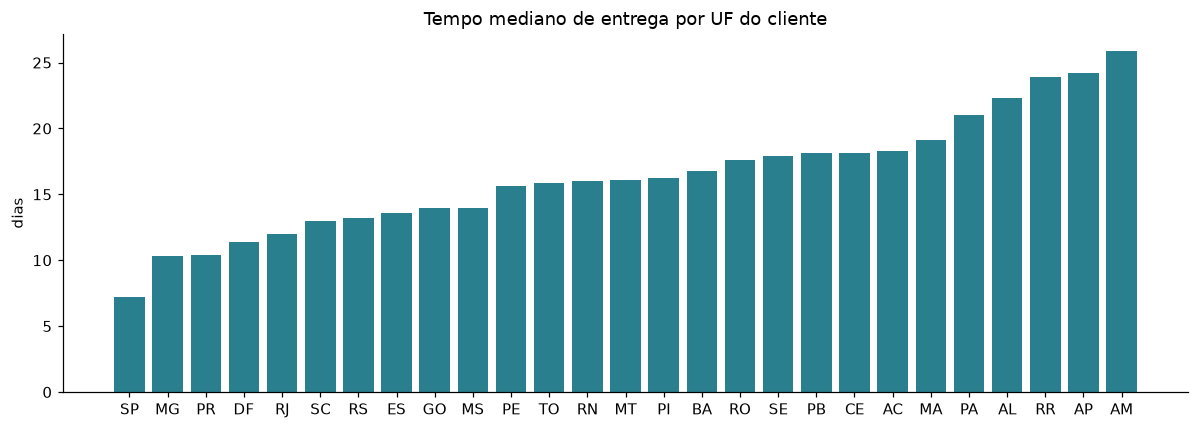

In [5]:
cat = data.groupby("customer_state")[of.TARGET].agg(pedidos="size", mediana="median").sort_values("mediana")
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(cat.index, cat.mediana, color="#2a7f8f")
ax.set(title="Tempo mediano de entrega por UF do cliente", ylabel="dias")
fig.tight_layout(); fig.savefig(FIG / "03_tempo_por_uf.png", dpi=150); plt.show()
cat.to_csv(TAB / "02_tempo_por_uf.csv")

## 3. Identificação de outliers (regra do IQR: abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR)

In [6]:
# só variáveis contínuas (em contagens/binárias o IQR é 0 e a regra não faz sentido)
cont = [of.TARGET, "products_value_total", "freight_value_total", "order_value_total", "weight_g_total",
        "volume_cm3_total", "length_cm_max", "height_cm_max", "width_cm_max", "distance_km_mean"]
rows = []
for c in cont:
    v = data[c].dropna(); q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
    n = int(((v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)).sum())
    rows.append({"variavel": c, "limite_inferior": q1 - 1.5 * iqr, "limite_superior": q3 + 1.5 * iqr, "outliers": n, "%": n / len(v) * 100})
outliers = pd.DataFrame(rows).sort_values("%", ascending=False)
outliers.to_csv(TAB / "02_outliers_iqr.csv", index=False)
outliers

,variavel,limite_inferior,limite_superior,outliers,%
4,weight_g_total,"-2,325.00","4,675.00",13482,14.02
2,freight_value_total,-1.41,39.23,9656,10.04
5,volume_cm3_total,"-22,364.62","45,178.38",8877,9.23
1,products_value_total,-110.10,305.90,7620,7.92
3,order_value_total,-109.71,347.68,7546,7.85
9,distance_km_mean,-730.88,"1,712.24",7378,7.71
7,height_cm_max,-10.00,38.00,6479,6.74
0,delivery_time_days,-6.49,28.83,4841,5.03
6,length_cm_max,-12.00,68.00,3121,3.25
8,width_cm_max,-7.50,52.50,2222,2.31


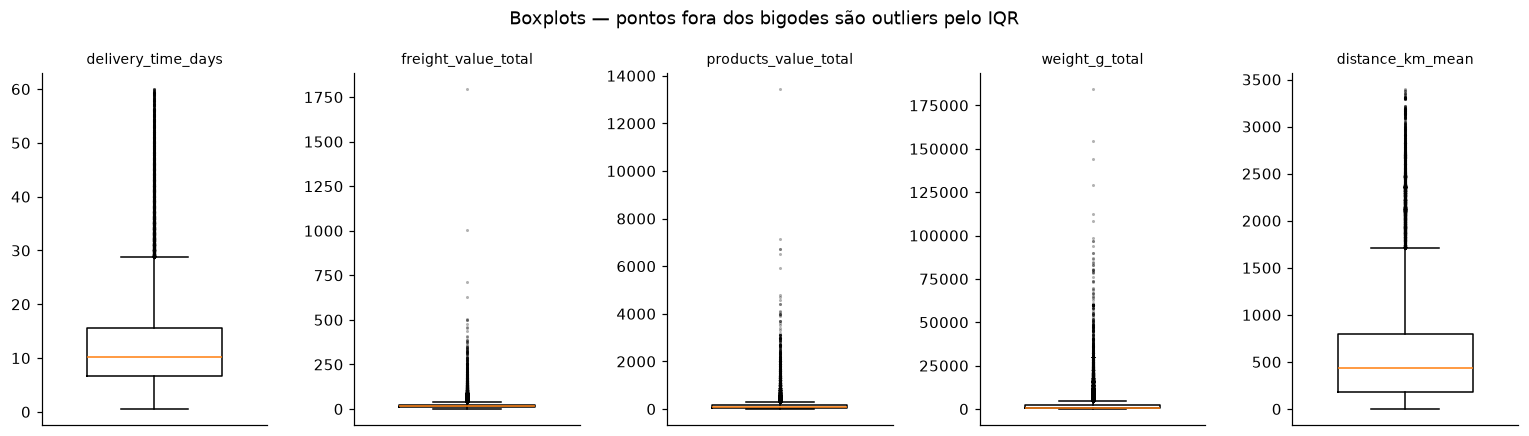

In [7]:
box = [of.TARGET, "freight_value_total", "products_value_total", "weight_g_total", "distance_km_mean"]
fig, axes = plt.subplots(1, len(box), figsize=(14, 4))
for ax, c in zip(axes, box):
    ax.boxplot(data[c].dropna(), flierprops={"marker": ".", "markersize": 2, "alpha": .3}, widths=.6)
    ax.set_title(c, fontsize=9); ax.set_xticks([])
fig.suptitle("Boxplots — pontos fora dos bigodes são outliers pelo IQR")
fig.tight_layout(); fig.savefig(FIG / "04_outliers_boxplot.png", dpi=150); plt.show()

Os outliers das features são **valores reais** (pedidos caros, pesados ou distantes) e foram mantidos;
para reduzir sua influência, o pré-processamento aplica `log1p` nas variáveis assimétricas e padronização.
No alvo, só as entregas acima de 60 dias foram removidas como ruído (notebook 01).

## 4. Matriz de correlações (Pearson)

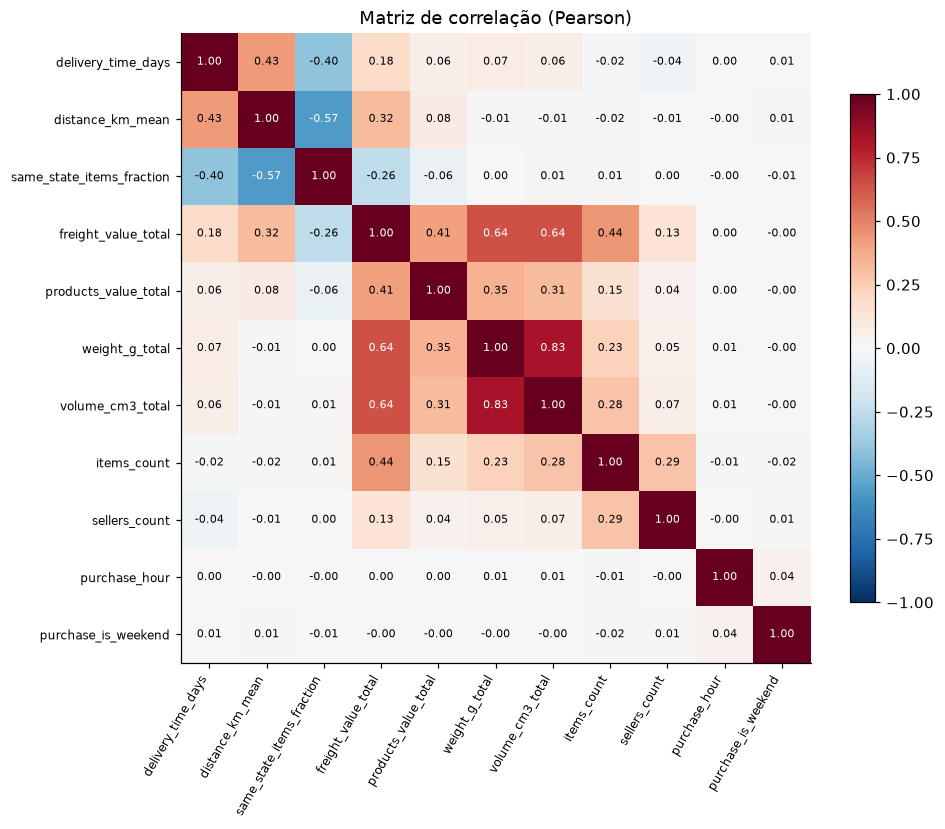

distance_km_mean             0.43
same_state_items_fraction   -0.40
freight_value_total          0.18
weight_g_total               0.07
volume_cm3_total             0.06
products_value_total         0.06
sellers_count               -0.04
items_count                 -0.02
purchase_is_weekend          0.01
purchase_hour                0.00
Name: delivery_time_days, dtype: float64

In [8]:
corr_cols = [of.TARGET, "distance_km_mean", "same_state_items_fraction", "freight_value_total", "products_value_total",
             "weight_g_total", "volume_cm3_total", "items_count", "sellers_count", "purchase_hour", "purchase_is_weekend"]
corr = data[corr_cols].corr()
corr.to_csv(TAB / "02_correlacoes.csv")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > .5 else "black")
fig.colorbar(im, shrink=.8); ax.set_title("Matriz de correlação (Pearson)")
fig.tight_layout(); fig.savefig(FIG / "05_matriz_correlacao.png", dpi=150); plt.show()
corr[of.TARGET].drop(of.TARGET).sort_values(key=abs, ascending=False)

## 5. Mapa geográfico (latitude × longitude do cliente)

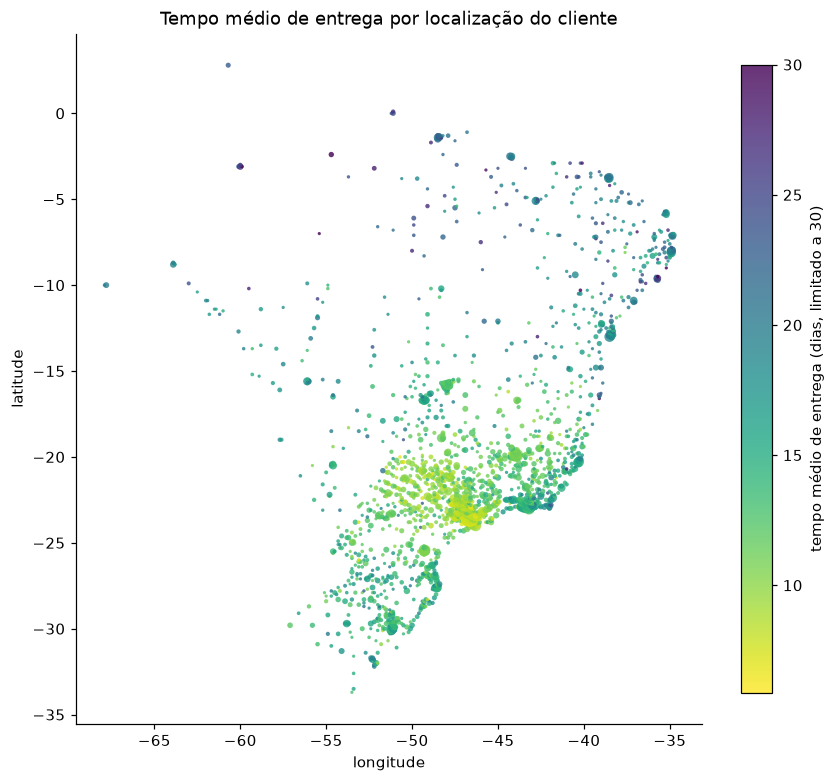

In [9]:
geo = data.dropna(subset=["customer_lat", "customer_lon"]).copy()
geo["lat_r"], geo["lon_r"] = geo.customer_lat.round(1), geo.customer_lon.round(1)
pts = geo.groupby(["lat_r", "lon_r"])[of.TARGET].agg(["mean", "size"]).reset_index()
pts = pts[pts["size"] >= 5]
fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(pts.lon_r, pts.lat_r, c=pts["mean"].clip(upper=30), s=np.sqrt(pts["size"]) * 2,
                cmap="viridis_r", alpha=.8, linewidths=0)
fig.colorbar(sc, label="tempo médio de entrega (dias, limitado a 30)", shrink=.75)
ax.set(title="Tempo médio de entrega por localização do cliente", xlabel="longitude", ylabel="latitude")
ax.set_aspect("equal"); fig.tight_layout(); fig.savefig(FIG / "06_mapa_tempo_entrega.png", dpi=150); plt.show()

## Principais conclusões da EDA

- O alvo é **assimétrico à direita** (média > mediana): a maioria chega em 1–2 semanas, alguns demoram muito mais.
- **Distância** é a variável mais correlacionada com o tempo; comprar de vendedor **da mesma UF** reduz o prazo.
- Norte/Nordeste têm prazos bem maiores que Sul/Sudeste (mapa e gráfico por UF), já que os vendedores se concentram em SP.
- Valores monetários e físicos têm caudas longas → justificam a transformação log e a padronização.